<a href="https://colab.research.google.com/github/jppeirce/DSC210-Foundations-of-Data-Science/blob/main/Homework/HW04-exploratory_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 4: Exploring Coffee Quality

**DSC 210 Foundations of Data Science**

*Covers Module 6 (pandas DataFrames) and Module 7 (exploratory data analysis).*

```
ASK  ->  GET  ->  [ EXPLORE ]  ->  MODEL  ->  COMMUNICATE
```

References:
- Module 6 and Module 7 course notebooks (the NYC taxi EDA is your model for this assignment)
- [Hands-on Introduction to Data Science with Python](https://florian-huber.github.io/data_science_course/) (CC BY-NC-SA 4.0)
- Coffee ratings data: [TidyTuesday, week of 2020-07-07](https://github.com/rfordatascience/tidytuesday/tree/main/data/2020/2020-07-07) (repository license CC0), from James LeDoux's [Coffee Quality Database](https://github.com/jldbc/coffee-quality-database) (MIT license), which was collected from the [Coffee Quality Institute](https://database.coffeeinstitute.org/) review pages in January 2018

*Last major revision: 2026-10-06*

## Key Concepts

- Run the **first-hour checklist** on a dataset you have never seen
- Tell how a column is *stored* from what it *means*, and repair a text date with `pd.to_datetime()`
- Summarize one variable at a time (frequency tables, histograms, boxplots) and pairs of variables (scatterplots, correlation heatmaps, group summaries, crosstabs)
- Investigate missing values, redundant columns, impossible values, and outliers, and decide whether each is an error or real
- Keep a **Question log** that grows and changes as you explore
- End with a **findings memo** that answers the original question with appropriate caution

## Instructions

**Total: 50 points.** Point values are listed with each problem.

- Cells marked `# RUN-TOGETHER` are complete; run them and read the output.
- Cells marked `# FILL-IN` contain blanks written as `____`. They raise an error until every blank is replaced.
- Run the cells **in order**. Later problems use columns and tables you create earlier (Problems A3c and B1).
- Every figure must include a title and labeled axes.
- Most of the credit rides on your written answers. Quote specific numbers from your output.
- This is an exploration, not a test of speed. Your **Question log** is graded: keep it honest, including the questions you could not answer.
- Submit the completed `.ipynb`, with all cells run and all figures visible, to Canvas.

---
## Part 0. The assignment and the data (2 points)
---

**The scenario.** You have just joined a small specialty coffee importer (a made-up company) as its first data analyst. The head buyer stops by your desk:

> *"Which countries and processing methods produce the highest-rated Arabica coffee? I want to know where to look for our next lot."*

This is **Q1** in your Question log. You will come back to it at the end.

**About the data.** The Coffee Quality Institute (CQI) trains professional tasters to grade coffee samples. Each graded sample gets ten sensory scores (aroma, flavor, sweetness, and so on) that add up to a total out of 100, plus information about where and how the coffee was grown and processed. In 2018, James LeDoux collected the public review pages into a table, and the TidyTuesday project republished it.

Two things to keep in mind from the start:

- These are coffees that someone **chose to submit** for grading. They are not a random sample of the world's coffee.
- The original data also contain 28 Robusta coffees, graded on a **different scoring form** (some of their columns measure different attributes than the Arabica columns with the same name). To keep comparisons fair, we keep only the Arabica coffees.

In [2]:
# RUN-TOGETHER  (setup)
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

url = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-07-07/coffee_ratings.csv'
coffee_all = pd.read_csv(url)

# Keep only the Arabica coffees. .copy() makes `coffee` its own table,
# so later changes to it do not affect coffee_all.
coffee = coffee_all[coffee_all['species'] == 'Arabica'].copy()

print('all coffees    :', coffee_all.shape)
print('Arabica coffees:', coffee.shape)

all coffees    : (1339, 43)
Arabica coffees: (1311, 43)


**Problem 0.** (2 points) Report the two shapes printed above, and how many rows were removed by keeping only Arabica. Then copy Q1 into your Question log below. You will add to this log at the end of every part.

**Your answer:**
This removes 28 coffees.

#### Your Question log

| # | Question | Raised in | Status |
| --- | --- | --- | --- |
| Q1 | Which countries and processing methods produce the highest-rated Arabica coffee? (the buyer's question) | Part 0 | open |

---
## Part A. First look (8 points)
---

Here is a short guide to the columns you will use most. Come back to it as you work.

| Column(s) | Meaning |
| --- | --- |
| `total_cup_points` | total grade, out of 100 |
| `aroma`, `flavor`, `aftertaste`, `acidity`, `body`, `balance`, `cupper_points` | sensory scores, each out of 10 |
| `uniformity`, `clean_cup`, `sweetness` | sensory scores out of 10 that mainly check for problem cups |
| `moisture` | moisture content of the green (unroasted) beans, as a fraction |
| `category_one_defects`, `category_two_defects`, `quakers` | counts of defective beans found in the sample |
| `country_of_origin`, `region`, `farm_name`, `owner`, `mill`, `company` | where the coffee came from and who handled it |
| `processing_method` | how the fruit was removed from the bean (for example washed, or dried whole) |
| `variety`, `color` | plant variety and bean color |
| `altitude`, `altitude_mean_meters` (and `_low_`, `_high_`) | growing altitude as typed by the submitter, and LeDoux's conversion to meters |
| `harvest_year`, `grading_date`, `expiration` | when the coffee was harvested, graded, and when the grade expires |

### Problem A1. Is the file in a random order? (2 points)

`head()` and `tail()` only show the ends of a file. If the file is sorted, the ends can be very misleading. Determine if the dataset has been sorted.

In [8]:
# Here is a good place to peek at the data.
coffee.head(10)

,total_cup_points,species,owner,country_of_origin,farm_name,lot_number,mill,ico_number,company,altitude,...,color,category_two_defects,expiration,certification_body,certification_address,certification_contact,unit_of_measurement,altitude_low_meters,altitude_high_meters,altitude_mean_meters
0,90.58,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,...,Green,0,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.0,2200.0,2075.0
1,89.92,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,...,Green,1,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.0,2200.0,2075.0
2,89.75,Arabica,grounds for health admin,Guatemala,"san marcos barrancas ""san cristobal cuch",NaN,NaN,NaN,NaN,1600 - 1800 m,...,NaN,0,"May 31st, 2011",Specialty Coffee Association,36d0d00a3724338ba7937c52a378d085f2172daa,0878a7d4b9d35ddbf0fe2ce69a2062cceb45a660,m,1600.0,1800.0,1700.0
3,89.00,Arabica,yidnekachew dabessa,Ethiopia,yidnekachew dabessa coffee plantation,NaN,wolensu,NaN,yidnekachew debessa coffee plantation,1800-2200,...,Green,2,"March 25th, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1800.0,2200.0,2000.0
4,88.83,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,...,Green,2,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.0,2200.0,2075.0
5,88.83,Arabica,ji-ae ahn,Brazil,NaN,NaN,NaN,NaN,NaN,NaN,...,Bluish-Green,1,"September 3rd, 2014",Specialty Coffee Institute of Asia,726e4891cf2c9a4848768bd34b668124d12c4224,b70da261fcc84831e3e9620c30a8701540abc200,m,NaN,NaN,NaN
6,88.75,Arabica,hugo valdivia,Peru,NaN,NaN,hvc,NaN,richmond investment-coffee department,NaN,...,Bluish-Green,0,"September 17th, 2013",Specialty Coffee Institute of Asia,726e4891cf2c9a4848768bd34b668124d12c4224,b70da261fcc84831e3e9620c30a8701540abc200,m,NaN,NaN,NaN
7,88.67,Arabica,ethiopia commodity exchange,Ethiopia,aolme,NaN,c.p.w.e,010/0338,NaN,1570-1700,...,NaN,0,"September 2nd, 2011",Ethiopia Commodity Exchange,a176532400aebdc345cf3d870f84ed3ecab6249e,61bbaf6a9f341e5782b8e7bd3ebf76aac89fe24b,m,1570.0,1700.0,1635.0
8,88.42,Arabica,ethiopia commodity exchange,Ethiopia,aolme,NaN,c.p.w.e,010/0338,NaN,1570-1700,...,NaN,0,"September 2nd, 2011",Ethiopia Commodity Exchange,a176532400aebdc345cf3d870f84ed3ecab6249e,61bbaf6a9f341e5782b8e7bd3ebf76aac89fe24b,m,1570.0,1700.0,1635.0
9,88.25,Arabica,diamond enterprise plc,Ethiopia,tulla coffee farm,NaN,tulla coffee farm,2014/15,diamond enterprise plc,1795-1850,...,Green,4,"March 29th, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1795.0,1850.0,1822.5


In [9]:
coffee.tail(10)

,total_cup_points,species,owner,country_of_origin,farm_name,lot_number,mill,ico_number,company,altitude,...,color,category_two_defects,expiration,certification_body,certification_address,certification_contact,unit_of_measurement,altitude_low_meters,altitude_high_meters,altitude_mean_meters
1301,70.75,Arabica,kurt kappeli,Mexico,various,NaN,f.i.e.c.h.,0016-2847-0001,globus coffee,1000 meters,...,Green,1,"May 5th, 2015",Specialty Coffee Association,36d0d00a3724338ba7937c52a378d085f2172daa,0878a7d4b9d35ddbf0fe2ce69a2062cceb45a660,m,1000.00,1000.00,1000.00
1302,70.67,Arabica,volcafe ltda. - brasil,Brazil,NaN,2017/2018 - Lot 2,copag,NaN,volcafe ltda.,NaN,...,Green,55,"October 27th, 2018",Brazil Specialty Coffee Association,3297cfa4c538e3dd03f72cc4082c54f7999e1f9d,8900f0bf1d0b2bafe6807a73562c7677d57eb980,m,NaN,NaN,NaN
1303,69.33,Arabica,cadexsa,Honduras,cerro bueno,NaN,cadexsa,13-63-174,cadexsa,1450 msnm,...,Green,4,"May 15th, 2015",Instituto Hondureño del Café,b4660a57e9f8cc613ae5b8f02bfce8634c763ab4,7f521ca403540f81ec99daec7da19c2788393880,m,1450.00,1450.00,1450.00
1304,69.17,Arabica,cadexsa,Honduras,cerro bueno,NaN,cadexsa,13-63-174,cadexsa,1450 msnm,...,Green,3,"May 15th, 2015",Instituto Hondureño del Café,b4660a57e9f8cc613ae5b8f02bfce8634c763ab4,7f521ca403540f81ec99daec7da19c2788393880,m,1450.00,1450.00,1450.00
1305,69.17,Arabica,cadexsa,Honduras,cerro bueno,NaN,cadexsa,13-63-174,cadexsa,1450 msnm,...,Green,4,"May 15th, 2015",Instituto Hondureño del Café,b4660a57e9f8cc613ae5b8f02bfce8634c763ab4,7f521ca403540f81ec99daec7da19c2788393880,m,1450.00,1450.00,1450.00
1306,68.33,Arabica,juan carlos garcia lopez,Mexico,el centenario,NaN,"la esperanza, municipio juchique de ferrer, ve...",1104328663,terra mia,900,...,NaN,20,"September 17th, 2013",AMECAFE,59e396ad6e22a1c22b248f958e1da2bd8af85272,0eb4ee5b3f47b20b049548a2fd1e7d4a2b70d0a7,m,900.00,900.00,900.00
1307,67.92,Arabica,myriam kaplan-pasternak,Haiti,200 farms,NaN,coeb koperativ ekselsyo basen (350 members),NaN,haiti coffee,~350m,...,Blue-Green,16,"May 24th, 2013",Specialty Coffee Association,36d0d00a3724338ba7937c52a378d085f2172daa,0878a7d4b9d35ddbf0fe2ce69a2062cceb45a660,m,350.00,350.00,350.00
1308,63.08,Arabica,"exportadora atlantic, s.a.",Nicaragua,finca las marías,017-053-0211/ 017-053-0212,beneficio atlantic condega,017-053-0211/ 017-053-0212,exportadora atlantic s.a,1100,...,Green,5,"June 6th, 2018",Instituto Hondureño del Café,b4660a57e9f8cc613ae5b8f02bfce8634c763ab4,7f521ca403540f81ec99daec7da19c2788393880,m,1100.00,1100.00,1100.00
1309,59.83,Arabica,juan luis alvarado romero,Guatemala,finca el limon,NaN,beneficio serben,11/853/165,unicafe,4650,...,Green,4,"May 24th, 2013",Asociacion Nacional Del Café,b1f20fe3a819fd6b2ee0eb8fdc3da256604f1e53,724f04ad10ed31dbb9d260f0dfd221ba48be8a95,ft,1417.32,1417.32,1417.32
1310,0.00,Arabica,bismarck castro,Honduras,los hicaques,103,cigrah s.a de c.v.,13-111-053,cigrah s.a de c.v,1400,...,Green,2,"April 28th, 2018",Instituto Hondureño del Café,b4660a57e9f8cc613ae5b8f02bfce8634c763ab4,7f521ca403540f81ec99daec7da19c2788393880,m,1400.00,1400.00,1400.00


(a) In one sentence: what does one row of `coffee` represent?

(b) In what order are the rows stored?

(c) Name two columns whose values look like labels or codes rather than measurements.

(d) Something in `tail()` should make you suspicious. What is it?

**Your answer:**

(a) Each row of coffee represents one coffee sample.

(b) Based on the output of head, we can see that the coffee is sorted in terms of total_cup_points

(c) certification_address	and certification_contact

(d) The cup of coffee with zero cup points is suspicious

### Problem A2. Read `info()` and `describe()` (2 points)

(a) How many columns have at least one missing value? Which column is missing the most?

(b) From the numeric `describe()`, list **three** values that look strange, odd, or impossible. Quote the numbers.

(c) Name three columns that hold numbers or dates but are stored as text (`object` or `str`).

**Your answer:**

(a) 19 columns, with lot_number having the most missing values.

(b) The value 190164.000000	for altitude_low_meters,	altitude_high_meters,	and altitude_mean_meters stands out for being unusually high in all three columns

(c) expiration, ico_number, and lot_number

In [10]:
# Code used for answer
coffee.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1311 entries, 0 to 1310
Data columns (total 43 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   total_cup_points       1311 non-null   float64
 1   species                1311 non-null   object 
 2   owner                  1304 non-null   object 
 3   country_of_origin      1310 non-null   object 
 4   farm_name              955 non-null    object 
 5   lot_number             270 non-null    object 
 6   mill                   1001 non-null   object 
 7   ico_number             1163 non-null   object 
 8   company                1102 non-null   object 
 9   altitude               1088 non-null   object 
 10  region                 1254 non-null   object 
 11  producer               1081 non-null   object 
 12  number_of_bags         1311 non-null   int64  
 13  bag_weight             1311 non-null   object 
 14  in_country_partner     1311 non-null   object 
 15  harvest_y

In [11]:
coffee.describe()

,total_cup_points,number_of_bags,aroma,flavor,aftertaste,acidity,body,balance,uniformity,clean_cup,sweetness,cupper_points,moisture,category_one_defects,quakers,category_two_defects,altitude_low_meters,altitude_high_meters,altitude_mean_meters
count,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000,1311.00000,1311.000000,1311.000000,1311.000000,1311.000000,1310.000000,1311.000000,1084.000000,1084.000000,1084.000000
mean,82.115927,153.887872,7.563806,7.518070,7.397696,7.533112,7.517727,7.517506,9.833394,9.83312,9.903272,7.497864,0.088863,0.426392,0.177099,3.591915,1759.548954,1808.843803,1784.196379
std,3.515761,129.733734,0.378666,0.399979,0.405119,0.381599,0.359213,0.406316,0.559343,0.77135,0.530832,0.474610,0.047957,1.832415,0.840583,5.350371,8767.847252,8767.187498,8767.016913
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,81.170000,14.500000,7.420000,7.330000,7.250000,7.330000,7.330000,7.330000,10.000000,10.00000,10.000000,7.250000,0.090000,0.000000,0.000000,0.000000,1100.000000,1100.000000,1100.000000
50%,82.500000,175.000000,7.580000,7.580000,7.420000,7.500000,7.500000,7.500000,10.000000,10.00000,10.000000,7.500000,0.110000,0.000000,0.000000,2.000000,1310.640000,1350.000000,1310.640000
75%,83.670000,275.000000,7.750000,7.750000,7.580000,7.750000,7.670000,7.750000,10.000000,10.00000,10.000000,7.750000,0.120000,0.000000,0.000000,4.000000,1600.000000,1650.000000,1600.000000
max,90.580000,1062.000000,8.750000,8.830000,8.670000,8.750000,8.580000,8.750000,10.000000,10.00000,10.000000,10.000000,0.280000,31.000000,11.000000,55.000000,190164.000000,190164.000000,190164.000000


### Problem A3. Type o' Data (3 points)

(a) Classify each column below as **numerical** (continuous or discrete), **categorical** (nominal or ordinal), **datetime**, or **identifier/text**. If a column could defensibly go two ways, say so.

| Column | Family | Reason (a few words) |
| --- | --- | --- |
| `total_cup_points` |  |  |
| `sweetness` |  |  |
| `category_two_defects` |  |  |
| `country_of_origin` |  |  |
| `processing_method` |  |  |
| `color` |  |  |
| `harvest_year` |  |  |
| `grading_date` |  |  |
| `certification_contact` |  |  |

In [17]:
# FILL-IN  (Problem A3b): what is actually stored in harvest_year?
print('distinct values:', len(coffee['harvest_year'].unique()))
print('The counts for each value in harvest_year\n')
coffee['harvest_year'].value_counts().head(20)

distinct values: 47
The counts for each value in harvest_year



,count
harvest_year,
2012,352
2014,226
2013,170
2015,125
2016,122
2017,68
2013/2014,29
2015/2016,28
2011,26


(b) `harvest_year` sounds like a simple year. Based on the output, why can it not be converted to a number as it stands? Give two example values.

(c) `grading_date` holds text such as `"April 4th, 2015"`. Repair it with `pd.to_datetime()`. Because the day has a suffix (`4th`, `31st`), add the argument `format='mixed'`, which tells pandas to work out the format value by value. Then derive the year and month of grading.

In [47]:
# FILL-IN  (Problem A3c)
coffee['grading_date'] = pd.to_datetime(coffee['grading_date'], format='mixed')

coffee['grading_year']  = coffee['grading_date'].dt.year
coffee['grading_month'] = coffee['grading_date'].dt.month

print('first grading date:', coffee['grading_date'].min())
print('last grading date :', coffee['grading_date'].max())
coffee['grading_year'].value_counts().sort_index()

first grading date: 2010-04-09 00:00:00
last grading date : 2018-01-19 00:00:00


,count
grading_year,
2010,50
2011,83
2012,314
2013,153
2014,246
2015,195
2016,123
2017,141
2018,6


**Your answer:**

(a) *(fill in the table above)*

(b) It cannot be converted to a number because it is a string and contains words or other non-number characters; for example: 'March 2010'. Some values contain time ranges such as: '2013/2014', which cannot be converted to one number

(c) Over what span of dates were these coffees graded, and which year has the most? These coffees were graded between 2010-04-09 and 2018-01-19, with the year 2012	having the most (314).

**Question log update (1 point).** Add **at least two** new questions (Q2, Q3, ...) raised by Part A. Use the "Raised in" column to say where each came from (for example `describe()` or `tail()`). Good questions are specific: *"Why is the minimum `total_cup_points` 0?"* beats *"Is the data clean?"*

| # | Question | Raised in | Status |
| --- | --- | --- | --- |
| Q1 | Which countries and processing methods produce the highest-rated Arabica coffee? | Part 0 | open |
| Q2 | Why is the minimum total_cup_points 0? | Part A | open |
| Q3 | Why is the maximum value for altitude_low_meters, altitude_high_meters, and altitude_mean_meters 190164.000000?| Part A | open |


---
## Part B. One variable at a time (12 points)
---

### Problem B1. What countries are in the sample? (3 points)

In [3]:
# FILL-IN  (Problem B1)
country_counts = coffee['country_of_origin'].value_counts()

# The 10 most common countries:
top10 = country_counts[1:10]
print(top10)

country_of_origin
Colombia                        183
Guatemala                       181
Brazil                          132
Taiwan                           75
United States (Hawaii)           73
Honduras                         53
Costa Rica                       51
Ethiopia                         44
Tanzania, United Republic Of     40
Name: count, dtype: int64


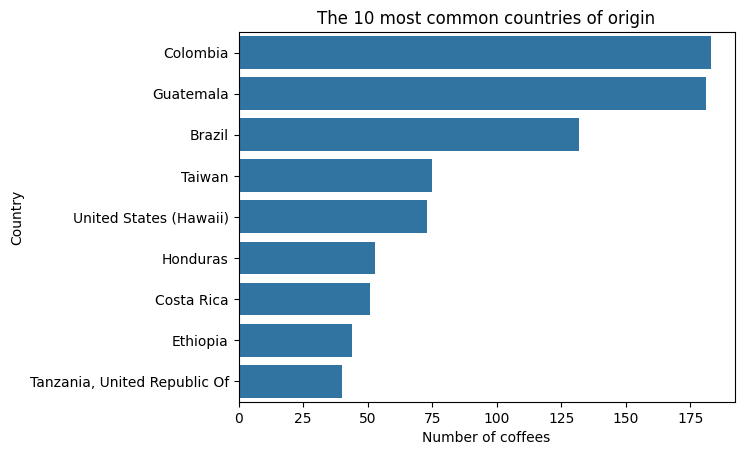

In [7]:
# FILL-IN  (Problem B1 continued)
# Plot top10
sns.countplot(data=coffee[coffee['country_of_origin'].isin(top10.index)],
              y='country_of_origin', order = top10.index)
plt.title('The 10 most common countries of origin')
plt.xlabel('Number of coffees')
plt.ylabel('Country')
plt.show()


In [8]:
# FILL-IN  (Problem B1 continued)
print('countries with fewer than 5 coffees:', coffee['country_of_origin'].value_counts()[coffee['country_of_origin'].value_counts() < 5].count())

countries with fewer than 5 coffees: 12


(a) What fraction of the coffees come from the three most common countries combined? (Use the counts printed above; there are 1,311 Arabica coffees in all.)

(b) How many countries contribute fewer than 5 coffees? Why does that matter if the buyer wants to know which **country** produces the best coffee?

**Your answer:**

(a) Colombia 183 + Guatemala 181 + Brazil 132 = 496 Total -> 496/1311 or 0.3783

(b) 12 countries, with countries with few coffees one coffee can skew the results of the country, lack of representation may also be an issue.

### Problem B2. The total score (3 points)

(a) Describe the shape of the distribution of total scores (`total_cup_points`) in one or two sentences. Is it symmetric, or skewed, and in which direction?

(b) Which bin count gives the more useful picture, and what does the other one hide or exaggerate?

(c) Compare the mean and the median. Which better describes a "typical" coffee here, and why?

(d) What does the boxplot show at the far left that the histograms make easy to miss?

count    1311.00
mean       82.12
std         3.52
min         0.00
25%        81.17
50%        82.50
75%        83.67
max        90.58
Name: total_cup_points, dtype: float64


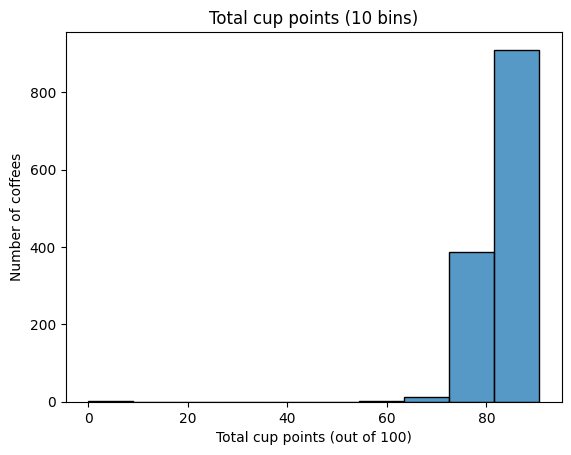

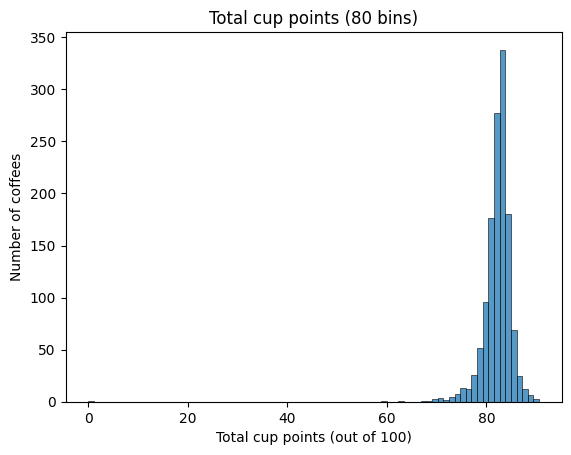

In [15]:
# FILL-IN  (Problem B2)
print(coffee['total_cup_points'].describe().round(2))

# The bins are a choice: try a coarse and a fine version.
for n_bins in [10,80]:
    sns.histplot(data=coffee, x='total_cup_points', bins=n_bins)
    plt.title(f'Total cup points ({n_bins} bins)')
    plt.xlabel('Total cup points (out of 100)')
    plt.ylabel('Number of coffees')
    plt.show()

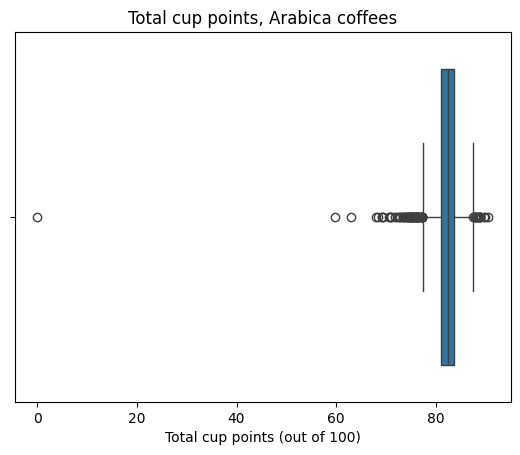

In [16]:
# FILL-IN  (Problem B2 continued)
sns.boxplot(data=coffee, x='total_cup_points')
plt.title('Total cup points, Arabica coffees')
plt.xlabel('Total cup points (out of 100)')
plt.show()

**Your answer:**

(a)It appears to be symetric with a median around 83 or so. There are a few lower outliers, but not enough to declare it as left-skewed.

(b) The higher bin count gives a more clear picture. The lower bin count has a bin cutoff in a weird spot making it appear left-skewed at a glance.

(c) The median would give a better measure of center, because although the distribution is mostly symettric, there is an outlier that may skew the mean.

(d) The boxplot shows the outlier at zero, which can be easy to miss in the histogram and can skew the mean.

### Problem B3. Which of the ten scores can tell coffees apart? (3 points)

The buyer wants to rank coffees. A score is only useful for ranking if coffees actually differ on it.

In [17]:
# FILL-IN  (Problem B3)
sensory = ['aroma', 'flavor', 'aftertaste', 'acidity', 'body', 'balance',
           'uniformity', 'clean_cup', 'sweetness', 'cupper_points']
scored = coffee[coffee['total_cup_points'] > 0]

spread = pd.DataFrame({'std':         scored[sensory].std(),
                       'iqr':         scored[sensory].quantile(0.75) - scored[sensory].quantile(0.25),
                       'proportion_at_10': (scored[sensory] == 10).mean()}).round(3)
spread.sort_values('iqr')

,std,iqr,proportion_at_10
uniformity,0.489,0.00,0.861
clean_cup,0.722,0.00,0.911
sweetness,0.455,0.00,0.930
aroma,0.316,0.33,0.000
aftertaste,0.350,0.33,0.000
body,0.293,0.34,0.000
acidity,0.320,0.42,0.000
flavor,0.342,0.42,0.000
balance,0.349,0.42,0.000
cupper_points,0.427,0.50,0.003


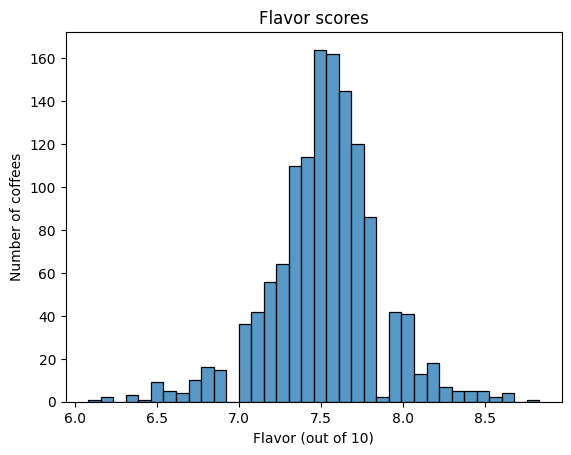

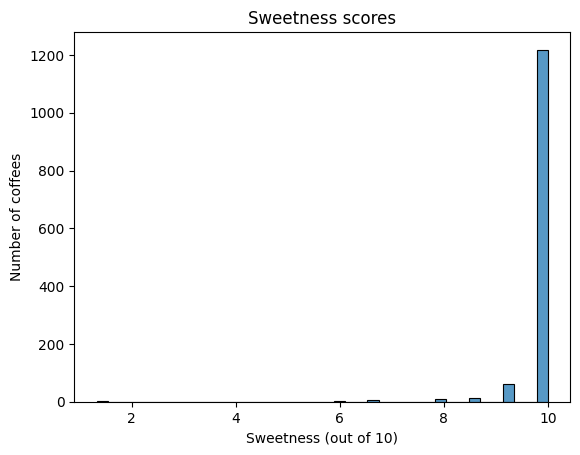

In [24]:
# FILL-IN  (Problem B3 continued)
# (ii) Compare the shapes: one score from the top of the table and one from the bottom.
sns.histplot(data=scored, x='flavor')
plt.title('Flavor scores')
plt.xlabel('Flavor (out of 10)')
plt.ylabel('Number of coffees')
plt.show()

# YOUR CODE: the same histogram for sweetness, fully labeled
sns.histplot(data=scored, x='sweetness', bins=40)
plt.title('Sweetness scores')
plt.xlabel('Sweetness (out of 10)')
plt.ylabel('Number of coffees')
plt.show()

(a) The ten scores fall into two groups in the table. Name the two groups and describe how the flavor and sweetness histograms differ in shape.


(b) For three scores the IQR is **0**, yet their standard deviations are among the **largest**. How can both be true? Use the sweetness histogram.

(c) Which scores carry most of the information for telling a good coffee from a very good one? What role do the other three play instead?

**Your answer:**

(a) They fall into groups of those with symetrical distibutions of scores and groups with scores that are skewed high.

(b) This can be true beacause a large prortion of the scores are at ten, enough to make the iqr be zero while still having some values spread across the graph, like in the sweetness histogram.

(c)The scores of aroma, aftertaste, body,	acidity,	flavor, and balance  carry information for telling a good coffee from a great one because the values are more evenly dispersed throughout the range, rather than being focused to one value like the other three scores.

### Problem B4. A suspicious spike (2 points)

In [25]:
# FILL-IN  (Problem B4)
# YOUR CODE: a fully labeled histogram of moisture with bins=40

zero_moisture = coffee['moisture'] == 0
print('moisture exactly 0:', zero_moisture.sum(), 'coffees | proportion:', round(zero_moisture.mean(), 3))
print(coffee[zero_moisture]['country_of_origin'].value_counts().head(5))
print(coffee.groupby(zero_moisture)['total_cup_points'].median())

moisture exactly 0: 252 coffees | proportion: 0.192
country_of_origin
Colombia                  77
Brazil                    31
United States (Hawaii)    27
Taiwan                    18
Mexico                    14
Name: count, dtype: int64
moisture
False    82.42
True     83.00
Name: total_cup_points, dtype: float64


Dried coffee beans always keep some water. Is a moisture of exactly 0 believable? What is the more likely explanation, and which country contributes most of these coffees? Would these values distort an average moisture?

**Your answer:** These values are likely due to some sort of rounding, but the true reason may be unknown. Columbia contibutes most of these and this would definitely distort the average.



**Question log update (1 point).** Add new questions from Part B, and mark any earlier question you can now close or sharpen.

| # | Question | Raised in | Status |
| --- | --- | --- | --- |
| Q1 | Which countries and processing methods produce the highest-rated Arabica coffee? | Part 0 | open |
| Q2 | Why is the minimum total_cup_points 0? | Part A | open |
| Q3 | Why is the maximum value for altitude_low_meters, altitude_high_meters, and altitude_mean_meters 190164.000000?| Part A | open |
| Q4 | Why is there a large proportion of coffees with moisture exactly zero | Part B | open |

---
## Part C. Pairs of variables (12 points)
---

### Problem C1. Does altitude go with quality? (3 points)

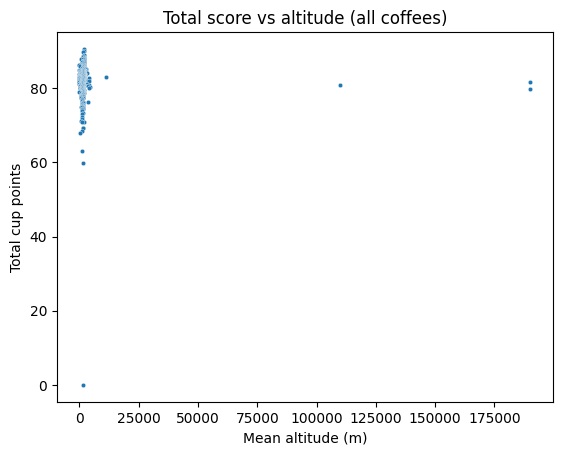

In [26]:
# RUN-TOGETHER  (Problem C1)
# (i) The first plot
sns.scatterplot(data=coffee, x='altitude_mean_meters', y='total_cup_points', s=10)
plt.title('Total score vs altitude (all coffees)')
plt.xlabel('Mean altitude (m)')
plt.ylabel('Total cup points')
plt.show()

This first plot is useless. (*Note:* The height of Mt. Everest is 8,848.86 meters.)

Create a mask that keeps coffees with a plausible altitude AND a real score (total above 0).

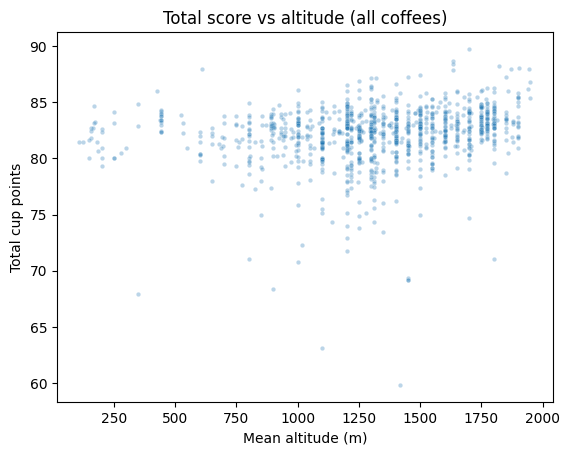

In [32]:
# (ii) YOUR CODE: keep coffees with a plausible altitude AND a real score (total above 0).
#      Choose your own altitude limits:

mask = (coffee['altitude_mean_meters']>100) & (coffee['altitude_mean_meters']<2000) & (coffee['total_cup_points'] > 50)
plausible = coffee[mask]

# (iii) YOUR CODE: redraw the scatterplot from `plausible`, adding alpha=0.3
#       so that places where many points overlap show up darker.
sns.scatterplot(data=plausible, x='altitude_mean_meters', y='total_cup_points', s=10, alpha=0.3)
plt.title('Total score vs altitude (all coffees)')
plt.xlabel('Mean altitude (m)')
plt.ylabel('Total cup points')
plt.show()

In [33]:
# RUN-TOGETHER  (Problem C1 continued)
print('r, all coffees:', round(coffee['altitude_mean_meters'].corr(coffee['total_cup_points']), 3))
print('r, plausible  :', round(plausible['altitude_mean_meters'].corr(plausible['total_cup_points']), 3),
      '| n =', len(plausible))

r, all coffees: -0.014
r, plausible  : 0.194 | n = 1032


Describe the relationship in the second plot (direction, strength) using its correlation. Compare it with the correlation coefficient of when the impossible values are included.

**Your answer:** There almost is no corelation when the the impossible values are included. Taking away those values makes the data somewhat corelated in the positive direction.



### Problem C2. The correlation heatmap (3 points)

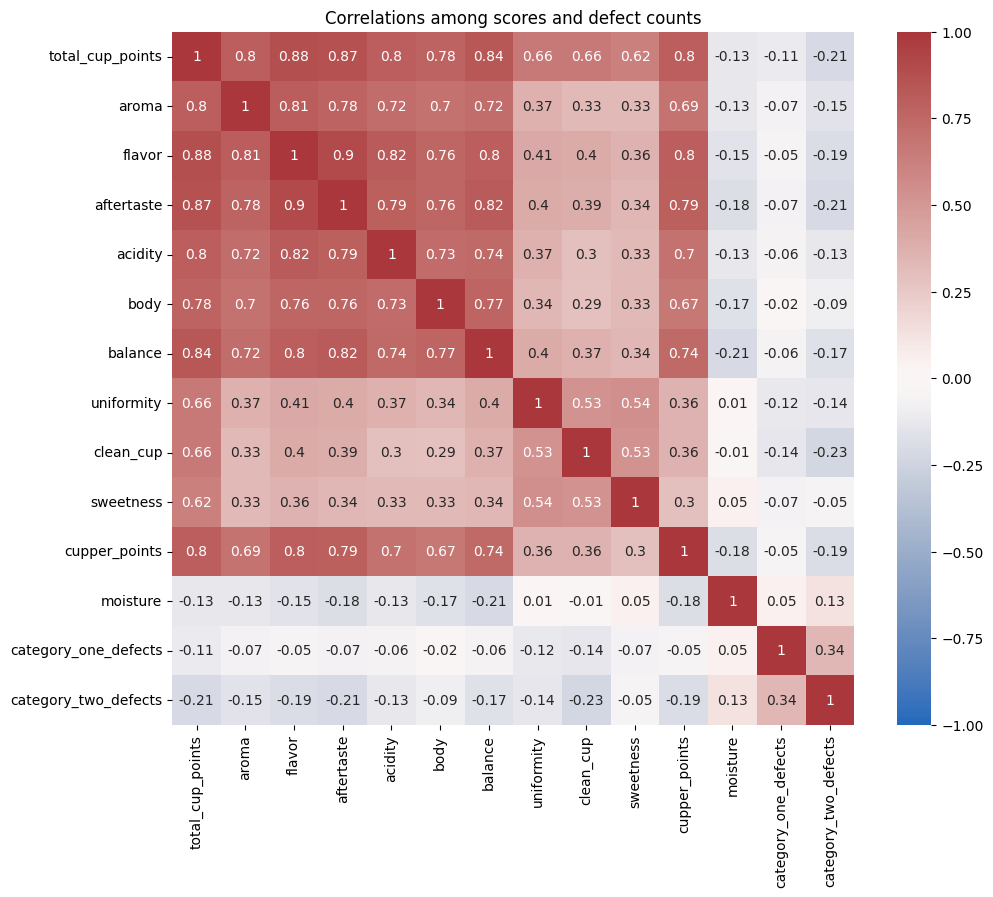

In [36]:
# FILL-IN  (Problem C2)
score_cols = ['total_cup_points', 'aroma', 'flavor', 'aftertaste', 'acidity', 'body',
              'balance', 'uniformity', 'clean_cup', 'sweetness', 'cupper_points',
              'moisture', 'category_one_defects', 'category_two_defects']

corr_matrix = coffee[score_cols].corr().round(2)

plt.figure(figsize=(11, 9))     # a bigger canvas so the labels fit
sns.heatmap(corr_matrix, annot=True, cmap='vlag', vmin=-1, vmax=1)
plt.title('Correlations among scores and defect counts')
plt.show()

In [37]:
# RUN-TOGETHER  (Problem C2c): how much can ONE coffee move a correlation?
no_zero = coffee[coffee['total_cup_points'] > 0]
for col in ['flavor', 'sweetness']:
    r_all = coffee[col].corr(coffee['total_cup_points'])
    r_no0 = no_zero[col].corr(no_zero['total_cup_points'])
    print(f'{col:10s} vs total:  all coffees r = {r_all:.3f}   without the 0-point coffee r = {r_no0:.3f}')

flavor     vs total:  all coffees r = 0.878   without the 0-point coffee r = 0.832
sweetness  vs total:  all coffees r = 0.617   without the 0-point coffee r = 0.435


(a) Leaving out `total_cup_points`, which pair of scores is most strongly correlated? What might explain it?

(b) Three of the sensory scores correlate only weakly with the other sensory scores. Which three, and how does Problem B3 explain it?

(c) Removing a single coffee changes one of these correlations a lot. Which one, by how much, and why is that coffee so influential?

**Your answer:**

(a) Flavor and aftertase are most strongly corelated this is likely because aftertase is somewhat of a subset of flavor.

(b) moisture, category one defects, and category two defects. These scores likely have something that is skewing the data to a certain area like in B3.

(c) Removing the zero point coffee changes the corelation of sweetness by 0.182 this is because it is highly sensitive to outliers.

### Problem C3. Comparing countries (2 points)

Countries with only a handful of coffees produce unreliable summaries (Problem B1), so we compare only countries with **at least 20** coffees.

In [38]:
# FILL-IN  (Problem C3)
big_countries = country_counts[country_counts >= 20].index
big = coffee[coffee['country_of_origin'].isin(big_countries)]

summary = (big.groupby('country_of_origin')['total_cup_points']
              .agg(['count', 'median', 'mean'])
              .sort_values('median', ascending=False)
              .round(2))
summary

,count,median,mean
country_of_origin,,,
Ethiopia,44,85.20,85.48
Kenya,25,84.58,84.31
Uganda,26,83.88,84.05
Colombia,183,83.25,83.11
Costa Rica,51,83.25,82.79
El Salvador,21,82.83,83.05
United States (Hawaii),73,82.75,81.82
Thailand,32,82.67,82.57
Indonesia,20,82.66,82.57


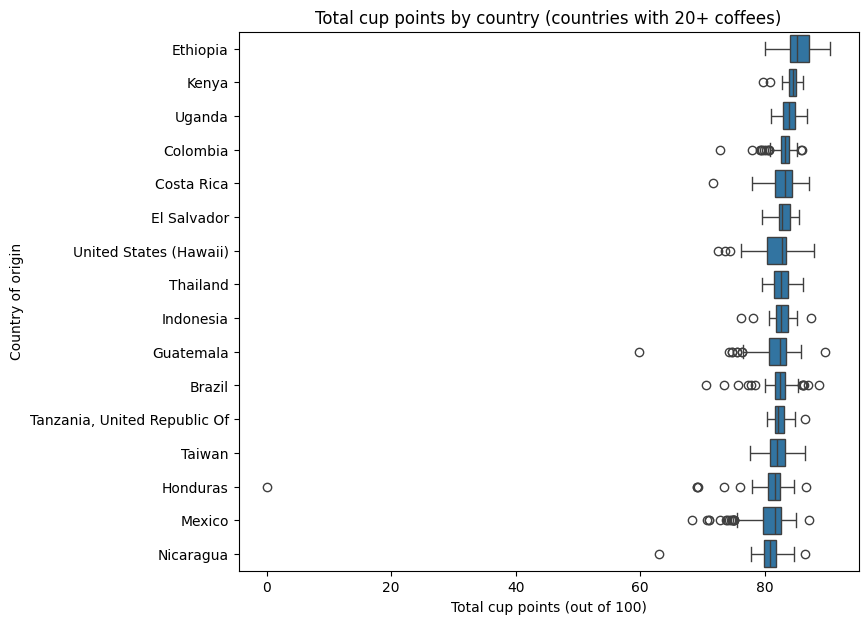

In [40]:
# FILL-IN  (Problem C3 continued)
plt.figure(figsize=(8, 7))
sns.boxplot(data=big, x='total_cup_points', y='country_of_origin', order=summary.index)
plt.title('Total cup points by country (countries with 20+ coffees)')
plt.xlabel('Total cup points (out of 100)')
plt.ylabel('Country of origin')
plt.show()

(a) Which three countries have the highest median score, and how large is the gap between the top and bottom countries in this table?

(b) For one country, the mean is far below the median. Which one, and what single coffee explains it? (Look at the boxplot.)

**Your answer:**

(a)Ethiopia, Kenya, Uganda. There is a gap of 4.36.

(b) Honduras, this is because of the zero score coffee.

### Problem C4. Two crosstabs (3 points)

In specialty coffee grading, a total of **85 or above** is commonly described as "excellent." We flag those coffees and compare processing methods.

In [42]:
# FILL-IN  (Problem C4)
coffee['excellent'] = coffee['total_cup_points'] >= 85

print(pd.crosstab(coffee['processing_method'], coffee['excellent']))
print()
print(pd.crosstab(coffee['processing_method'], coffee['excellent'], normalize='index').round(3))

excellent                  False  True 
processing_method                      
Natural / Dry                223     28
Other                         26      0
Pulped natural / honey        13      1
Semi-washed / Semi-pulped     50      6
Washed / Wet                 767     45

excellent                  False  True 
processing_method                      
Natural / Dry              0.888  0.112
Other                      1.000  0.000
Pulped natural / honey     0.929  0.071
Semi-washed / Semi-pulped  0.893  0.107
Washed / Wet               0.945  0.055


In [43]:
# FILL-IN  (Problem C4 continued)
top8 = country_counts.head(8).index
top8_coffee = coffee[coffee['country_of_origin'].isin(top8)]

pd.crosstab(top8_coffee['country_of_origin'], top8_coffee['excellent'],
            normalize='index').round(2)

excellent,False,True
country_of_origin,,
Brazil,0.94,0.06
Colombia,0.96,0.04
Costa Rica,0.90,0.10
Guatemala,0.95,0.05
Honduras,0.98,0.02
Mexico,0.99,0.01
Taiwan,0.97,0.03
United States (Hawaii),0.86,0.14


(a) Which processing method has the highest proportion of excellent coffees? Quote the proportion and the count behind it.

(b) Use the second crosstab: why is it risky to conclude that the processing method *causes* the higher scores? Name the lurking variable.

**Your answer:**

(a) Natural / Dry has the highest proportion of 0.112 being excelent coffees.

(b) The processing method does not conclusively tell this because other varriable also have an effect on the proportion of excellent coffees. In the second crosstab we can see that the country of origin has an impact on the proportion of excellent coffees.


**Question log update (1 point).** Add new questions from Part C, and update the status of earlier ones. You should now have real evidence on Q1: record it in the Status column.
| # | Question | Raised in | Status |
| --- | --- | --- | --- |
| Q1 | Which countries and processing methods produce the highest-rated Arabica coffee? | Part 0 | *closed C4* |
| Q2 | Why is the minimum total_cup_points 0? | Part A | open |
| Q3 | Why is the maximum value for altitude_low_meters, altitude_high_meters, and altitude_mean_meters 190164.000000?| Part A | *closed C1* |
| Q4 | Why is there a large proportion of coffees with moisture exactly zero | Part B | open |
| Q5 | Which varriable causes the score of coffees to be excelent?|Part C| open |
| Q6 | Which processing method has the highest proportion of excellent coffees? | Part C | closed C4 |

---
## Part D. Missing values and data quality (8 points)
---

### Problem D1. Where are the holes, and are they random? (3 points)

In [44]:
# FILL-IN  (Problem D1)
pct_missing = (coffee.isna().mean() * 100).round(1)
pct_missing[pct_missing > 0].sort_values(ascending=False)

,0
lot_number,79.4
farm_name,27.2
mill,23.6
color,20.4
producer,17.5
altitude_high_meters,17.3
altitude_low_meters,17.3
altitude_mean_meters,17.3
altitude,17.0
company,15.9


In [48]:
# FILL-IN  (Problem D1 continued)
# An indicator column: True where processing_method is missing.
coffee['proc_missing'] = coffee['processing_method'].isna()

# (i) Does the missing rate depend on WHEN the coffee was graded?
print(coffee.groupby('grading_year')['proc_missing'].mean().round(2))
print()
# (ii) Do coffees with a missing processing method score differently?
coffee.groupby('proc_missing')['total_cup_points'].describe().round(2)

grading_year
2010    1.00
2011    0.82
2012    0.00
2013    0.00
2014    0.00
2015    0.01
2016    0.18
2017    0.07
2018    0.00
Name: proc_missing, dtype: float64



,count,mean,std,min,25%,50%,75%,max
proc_missing,,,,,,,,
False,1159.0,82.08,2.70,59.83,81.08,82.42,83.58,90.58
True,152.0,82.42,7.17,0.00,81.67,83.08,84.33,89.75


(a) Which columns are missing for more than 20% of coffees?

(b) Is the missingness of `processing_method` random? Use the missing rate by grading year as evidence.

(c) Compare the scores of coffees with and without a recorded processing method. If an analyst simply dropped every row with a missing processing method before answering Q1, what might go wrong?

**Your answer:**

(a) lot_number, farm_name, mill, color

(b) from 2010 to 2011 the missing rate of processing method is very high. This shows that the missingness of processing method is not random and it has to do with those two years.

(c) If every row was dropped this would affect the standard deviation of the data. The mremoval of the outlier would have an effect on the data. Also removing these values could remove high quality coffees as shown by the max (89.75.)

### Problem D2. Duplicates and columns that say the same thing twice (2 points)

In [49]:
# RUN-TOGETHER  (Problem D2)
print('duplicated rows:', coffee.duplicated().sum())

# owner vs owner_1: compare after converting both to lower case.
# (.str.lower() works on every text value in a column, like .str.contains() in Module 7.)
same_owner = coffee['owner'].str.lower() == coffee['owner_1'].str.lower()
print('owner equals owner_1 (ignoring case):', round(same_owner.mean(), 3))

# expiration vs grading_date
expiration = pd.to_datetime(coffee['expiration'], format='mixed')
print((expiration - coffee['grading_date']).value_counts())

# total_cup_points vs the sum of the ten sensory scores
sensory = ['aroma', 'flavor', 'aftertaste', 'acidity', 'body', 'balance',
           'uniformity', 'clean_cup', 'sweetness', 'cupper_points']
gap = (coffee[sensory].sum(axis=1) - coffee['total_cup_points']).abs()
print('largest gap between the sum of scores and the total:', gap.max())

duplicated rows: 0
owner equals owner_1 (ignoring case): 0.99
365 days    1311
Name: count, dtype: int64
largest gap between the sum of scores and the total: 0.5


There are no duplicated rows, but some *columns* repeat information. Name the columns that add nothing new, and explain how you know from the output. Why might it still be worth keeping one of them?

**Your answer:** Owner equals Owner_1 99% of the time according to the second row of output. The total scores is almost equal to the sum of the scores according to the last row of output. It is useful to keep at least one owner so we have this information. It is useful to keep the total socres because it is a helpful culmination of data.

### Problem D3. Outliers in the total score: error or real? (2 points)

In [50]:
# FILL-IN  (Problem D3)
q1 = coffee['total_cup_points'].quantile(0.25)
q3 = coffee['total_cup_points'].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print('fences:', round(lower, 2), 'to', round(upper, 2))
print('below the lower fence:', (coffee['total_cup_points'] < lower).sum())
print('above the upper fence:', (coffee['total_cup_points'] > upper).sum())

show = ['total_cup_points', 'country_of_origin', 'uniformity', 'clean_cup',
        'sweetness', 'category_one_defects']
print(coffee.sort_values('total_cup_points')[show].head(4))
print(coffee.sort_values('total_cup_points', ascending=False)[show].head(3))

fences: 77.42 to 87.42
below the lower fence: 58
above the upper fence: 16
      total_cup_points country_of_origin  uniformity  clean_cup  sweetness  \
1310              0.00          Honduras        0.00       0.00       0.00   
1309             59.83         Guatemala        8.00       1.33       1.33   
1308             63.08         Nicaragua        6.00       6.00       6.00   
1307             67.92             Haiti        9.33       6.00       6.00   

      category_one_defects  
1310                     0  
1309                     0  
1308                     1  
1307                     8  
   total_cup_points country_of_origin  uniformity  clean_cup  sweetness  \
0             90.58          Ethiopia        10.0       10.0       10.0   
1             89.92          Ethiopia        10.0       10.0       10.0   
2             89.75         Guatemala        10.0       10.0       10.0   

   category_one_defects  
0                     0  
1                     0  
2         

Look at the four lowest and three highest coffees. Which do you think are data errors, and which are real (if unusual) coffees? Cite the columns that support each call.

**Your answer:**
The row 1310 is likely a data error as all columns are zero. The rest seem to be real, however, row 1309 seems unusual because it has a uniformity of 8 and a clean cup and sweetness of 1.33 this seems to be an unusual pairing.


**Question log update (1 point).** Add new questions from Part D and update every status.

| # | Question | Raised in | Status |
| --- | --- | --- | --- |
| Q1 | Which countries and processing methods produce the highest-rated Arabica coffee? | Part 0 | closed C4 |
| Q2 | Why is the minimum total_cup_points 0? | Part A | *Closed D3* |
| Q3 | Why is the maximum value for altitude_low_meters, altitude_high_meters, and altitude_mean_meters 190164.000000?| Part A | closed C1 |
| Q4 | Why is there a large proportion of coffees with moisture exactly zero | Part B | open |
| Q5 | Which varriable causes the score of coffees to be excelent?|Part C| open |
| Q6 | Which processing method has the highest proportion of excellent coffees? | Part C | closed C4 |
| Q7 | Should every row with a missing processing method be dropped|Part D| closed D1 |

---
## Part E. Findings memo (8 points)
---

Every EDA session ends with written findings. Write yours for the buyer.

**(a) (2 points) Final Question log.** Copy your full log here. Every question needs a status: *closed* (with where), *open*, or *cannot be answered with this data* (with why).

| # | Question | Raised in | Status |
| --- | --- | --- | --- |
| Q1 | Which countries and processing methods produce the highest-rated Arabica coffee? | Part 0 | closed C4 |
| Q2 | Why is the minimum total_cup_points 0? | Part A | closed D3 |
| Q3 | Why is the maximum value for altitude_low_meters, altitude_high_meters, and altitude_mean_meters 190164.000000?| Part A | closed C1 |
| Q4 | Why is there a large proportion of coffees with moisture exactly zero | Part B | open |
| Q5 | Which varriable causes the score of coffees to be excelent?|Part C| open |
| Q6 | Which processing method has the highest proportion of excellent coffees? | Part C | closed C4 |
| Q7 | Should every row with a missing processing method be dropped|Part D1| closed D1|

**(b) (2 points) Answer to Q1.** In 2 to 4 sentences, answer the buyer's question. Quote specific numbers.
The Natural / Dry method tends to give the largest proportion of high rated coffee with 0.112 of coffees being excellent by this method. Brazil, Costa Rica, United States (Hawaii)	had the largest proportion of excelent coffes with 0.06, 0.10, and 0.14 respectively

**(c) (2 points) Other findings.** List at least five numbered findings, each with a specific number. Include at least one about data quality.

1. The minimum total cups was a data error with cup score 0(bad data quality)
2. The maximum values for altitude_low_meters, altitude_high_meters, and altitude_mean_meters were unplausable at 190164 (bad data quality)
3. Natural / Dry method tends to give the largest proportion of high rated coffee of 0.112
4. Brazil, Costa Rica, United States (Hawaii)	had the largest proportion of excelent coffes with 0.06, 0.10, and 0.14 respectively
5. If every row with a missing processing method was dropped it could remove high quality coffees as shown by the maximum from these missing rows (89.75.)

**(d) (2 points) Hand-off to cleaning.** Module 8 is about *deciding* what to do with the problems you found. List at least four cleaning decisions this dataset will need. For each: the problem, the decision you would make (fix, drop, flag, or keep), and one sentence on why.

| Problem | Decision | Why |
| --- | --- | --- |
|  |  |  |